In [1]:
import os
import torch
import pandas as pd
import scanpy as sc
from sklearn import metrics
import multiprocessing as mp
from STWaveGraph.STWaveGraph import STWaveGraph
import matplotlib.pyplot as plt

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
import rpy2

In [3]:
dataset = 'Mouse_Brain_Anterior'
n_clusters = 52
file_fold = '/root/workspace/STWaveGraph-main/Data/' + str(dataset) #please replace 'file_fold' with the download path
adata = sc.read_visium(file_fold, count_file='filtered_feature_bc_matrix.h5', load_images=True)
adata.var_names_make_unique()

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/_core/anndata.py:1830: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [4]:
import torch
print("PyTorch版本:", torch.__version__)
print("CUDA是否可用:", torch.cuda.is_available())

PyTorch版本: 2.4.1+cu124
CUDA是否可用: True


73:600:3500:random seed: 6497
6382:0.671
76:seed: 5549:0.603
510:seed: 8951:0.516

In [ ]:
model = STWaveGraph(
    adata=adata,
    n_clusters=n_clusters, 
    device=device,
    n_top_genes=3000,          
    pca_dim=50,                
    n_neighbors_spatial=6,    
    expr_power=0.8,            

    hidden_dim=128,            
    proj_dim=64,               
    n_bands=4,                
    spectral_k=192,            
    spectral_low_ratio=0.60,   
    
    pretrain_epochs=300,       
    finetune_epochs=200,       

    lambda_rec=0.30,
    lambda_ssl=1.0,           
    lambda_smooth=0.05,        
    lambda_kl=1.0,             
    lambda_balance=0.08,       
    lambda_boundary=0.15,      
    boundary_margin=1.0,

    cluster_method="mclust",
    cluster_pca_dim=20,       
    mclust_model="EEE",        
    refine_iters=2,
    
    random_seed=2024
)
adata = model.train(verbose=True)

========== Stage 1: Representation Pretraining ==========


100%|██████████| 300/300 [01:43<00:00,  2.89it/s]


========== Initialize Cluster Centers ==========
========== Stage 2: Clustering Finetuning ==========


 26%|██▌       | 51/200 [00:17<00:33,  4.46it/s]

[Finetune] Epoch 50/200 | loss=0.9954 | rec=2.2307 | ssl=0.2156 | smooth=0.1950 | kl=0.0439 | balance=0.0030 | bd=0.3772 | extra_reg_on=1


...

[Finetune] Epoch 100/200 | loss=0.8756 | rec=2.0679 | ssl=0.1404 | smooth=0.2038 | kl=0.0495 | balance=0.0030 | bd=0.3645 | extra_reg_on=1


 75%|███████▌  | 150/200 [00:53<00:13,  3.61it/s]

[Finetune] Epoch 150/200 | loss=0.7894 | rec=1.9278 | ssl=0.0917 | smooth=0.2131 | kl=0.0547 | balance=0.0029 | bd=0.3571 | extra_reg_on=1


100%|██████████| 200/200 [01:11<00:00,  2.82it/s]


[Finetune] Epoch 200/200 | loss=0.7228 | rec=1.7995 | ssl=0.0604 | smooth=0.2193 | kl=0.0588 | balance=0.0027 | bd=0.3494 | extra_reg_on=1
fitting ...
  |======================================================================| 100%


In [7]:
# model = STWaveGraph(
#     adata=adata,
#     n_clusters=n_clusters,
#     device=device,

#     n_top_genes=3500,
#     pca_dim=80,
#     n_neighbors_spatial=7,
#     expr_power=1.3,

#     hidden_dim=128,
#     proj_dim=64,
#     n_bands=4,
#     spectral_k=192,
#     spectral_low_ratio=0.60,

#     pretrain_epochs=280,
#     finetune_epochs=250,

#     lambda_rec=0.30,
#     lambda_ssl=0.45,
#     lambda_smooth=0.030,
#     lambda_kl=0.9,
#     lambda_balance=0.0,
#     lambda_boundary=0.15,
#     boundary_margin=1.0,

#     cluster_method="mclust",
#     cluster_pca_dim=35,
#     mclust_model="VVV",
#     refine_iters=2,

#     random_seed=2024
# )
# adata = model.train(verbose=True)

In [8]:
# add ground_truth
df_meta = pd.read_csv(file_fold + '/metadata.tsv', sep='\t')
df_meta_layer = df_meta['ground_truth']
adata.obs['ground_truth'] = df_meta_layer.values

In [9]:
adata

AnnData object with n_obs × n_vars = 2695 × 32285
    obs: 'in_tissue', 'array_row', 'array_col', 'pred_domain_raw', 'pred_domain', 'ground_truth'
    var: 'gene_ids', 'feature_types', 'genome', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'mean', 'std'
    uns: 'spatial', 'hvg', 'log1p', 'cluster_method_used', 'cluster_pca_dim', 'mclust_model', 'regularization_warmup_epochs'
    obsm: 'spatial', 'emb', 'model_q', 'soft_assign'

In [11]:
adata.obsm['emb']

array([[-0.04921696, -0.06986949, -0.02635035, ..., -0.0294026 ,
        -0.01329974, -0.05385238],
       [-0.04801746, -0.04777866, -0.01431055, ..., -0.10406859,
         0.11066584, -0.02991691],
       [ 0.09364976,  0.06159861,  0.20516829, ..., -0.01766913,
         0.02165904,  0.06544186],
       ...,
       [-0.109222  ,  0.00855863,  0.01565913, ..., -0.04955881,
         0.15527162,  0.11109376],
       [-0.03257529,  0.12570433,  0.10485515, ..., -0.09297214,
        -0.05476388,  0.1932492 ],
       [ 0.0430052 , -0.01043233,  0.12582254, ..., -0.18341242,
        -0.04003888,  0.09473847]], dtype=float32)

In [12]:
# filter out NA nodes
adata = adata[~pd.isnull(adata.obs['ground_truth'])]

# calculate metric ARI
ARI = metrics.adjusted_rand_score(adata.obs['pred_domain'], adata.obs['ground_truth'])
adata.uns['ARI'] = ARI

print('Dataset:', dataset)
print('ARI:', ARI)

/opt/conda/envs/SpatioFrep/lib/python3.8/site-packages/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


Dataset: Mouse_Brain_Anterior
ARI: 0.46057942200098834


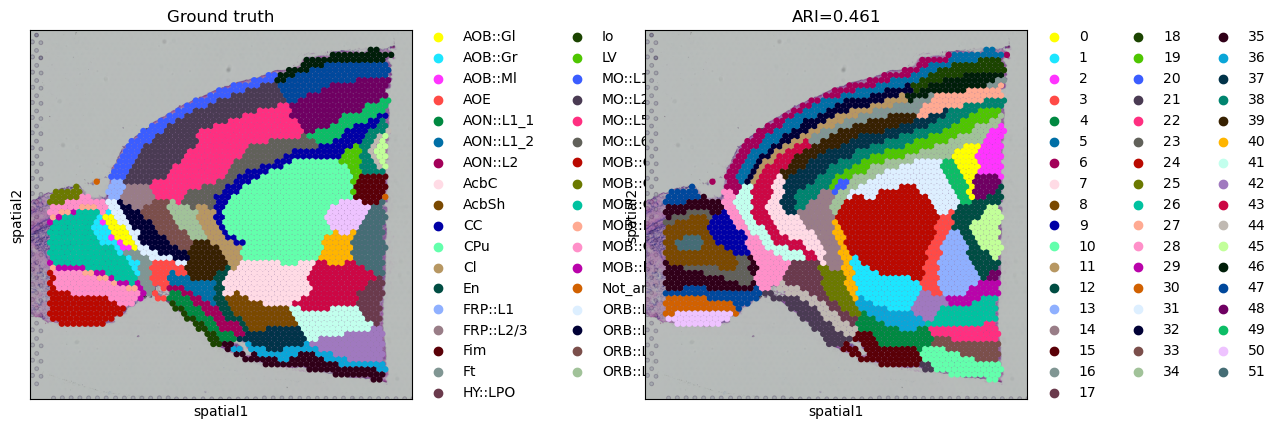

In [ ]:
sc.pl.spatial(
    adata,
    img_key="hires",
    color=["ground_truth", "pred_domain"],
    title=["Ground truth", f"ARI={ARI:.3f}"],
    spot_size=150,
    show=True
)
